### generator is the simple way of creating iterator

In [2]:
#iterable
class mera_range:
    def __init__(self,start,end,diff):
        self.s=start
        self.e=end
        self.d=diff
    def __iter__(self):
        return mera_range_iterator(self)

#iterator
class mera_range_iterator:
    def __init__(self,iterable_obj):
        self.iterable=iterable_obj
    def  __iter__(self):
        return self
    def __next__(self):
        if self.iterable.s>=self.iterable.e:
            raise StopIteration
        
        curr=self.iterable.s
        self.iterable.s+=self.iterable.d
        return curr


In [7]:
L = [x for x in range(100000)]

#for i in L:
    #print(i**2)
    
import sys
sys.getsizeof(L)  #800984 bytes (too much space) becoz it store all these numbers


x = range(1000000)

#for i in x:
    #print(i**2)
sys.getsizeof(x) #48 bytes (too short) it stores only start,end,step
#You can instantly get items by index (e.g., x[500] returns 500) without generating the preceding numbers.

48

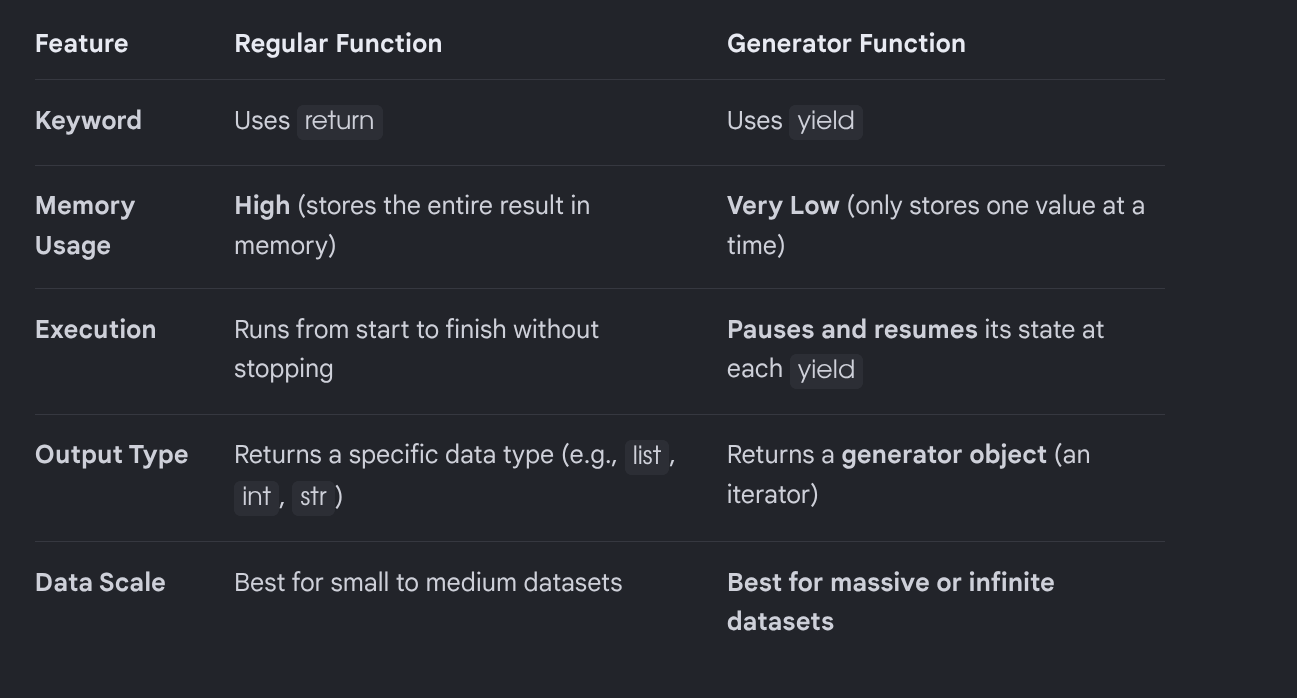

A generator uses yield. When called, it doesn't run the code immediately; it returns a generator object. Every time you ask for the next value (like in a for loop), it runs until it hits yield, gives you that value, and freezes its exact state until you ask for the next one

In [13]:
def get_squared_gen(num):
    for i in range(num):
        yield i**2 # Pauses here, remembers state, and hands over one number
    
# This takes virtually ZERO memory right now
my_gen=get_squared_gen(1000) 

# type(my_gen) #generator

for num in my_gen:
    print(num)
    break 

0


In [ ]:
def square(num):
    for i in range(num):
        yield i**2
    
gen=square(10) #generator
print(next(gen)) #0
print(next(gen)) #1
print(next(gen)) #4
for i in gen:    #9 16 .... 81 continued from 9 not from 0 
    print(i) 

0
1
4
9
16
25
36
49
64
81


In [19]:
#mera range function using generator

def mera_range(start,end):
    for i in range(start,end):
        yield i

for i in mera_range(12,23):
    print(i)

12
13
14
15
16
17
18
19
20
21
22


In [22]:
l=[i**2 for i in range(1,2000000)] #list
sys.getsizeof(l)

17128280

In [23]:
gen=(i**2 for i in range(1,2000000))
sys.getsizeof(gen)

200

# practical example for dl

In [29]:
!pip install kagglehub 


In [39]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ananthu017/emotion-detection-fer")

print("Path to dataset files:", path)

100%|██████████| 65.2M/65.2M [00:05<00:00, 12.4MB/s]

Extracting files...


Path to dataset files: /home/abhishek/.cache/kagglehub/datasets/ananthu017/emotion-detection-fer/versions/1


In [ ]:
!pip install opencv-python


  Using cached opencv_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl (73.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 11.3 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [opencv-python]0m [opencv-python]


In [33]:
import os 
import cv2 

def image_data_reader(folder_path):

    for file in os.listdir(folder_path):
        f_array=cv2.imread(os.path.join(folder_path,file))
        yield f_array

In [ ]:
/home/abhishek/testgen=image_data_reader("/home/abhishek/test/sad")
print(next(gen))

[[[132 132 132]
  [133 133 133]
  [139 139 139]
  ...
  [186 186 186]
  [186 186 186]
  [186 186 186]]

 [[130 130 130]
  [133 133 133]
  [133 133 133]
  ...
  [186 186 186]
  [186 186 186]
  [186 186 186]]

 [[129 129 129]
  [132 132 132]
  [133 133 133]
  ...
  [186 186 186]
  [187 187 187]
  [186 186 186]]

 ...

 [[101 101 101]
  [102 102 102]
  [102 102 102]
  ...
  [184 184 184]
  [203 203 203]
  [179 179 179]]

 [[101 101 101]
  [104 104 104]
  [103 103 103]
  ...
  [183 183 183]
  [201 201 201]
  [182 182 182]]

 [[102 102 102]
  [101 101 101]
  [104 104 104]
  ...
  [175 175 175]
  [202 202 202]
  [181 181 181]]]
